# Homework 10 hints and checks

Open this notebook after you have written an answer to every part of [Homework 10](https://colab.research.google.com/github/wfreinhart/matse219/blob/main/notebooks/Homework10.ipynb).

Each warm-up prompt is repeated here with a check cell that runs its code, so run it only after writing your prediction.
Each exam-style question has two hints and then the answer, each one nested inside the one before it.
> Open a hint only after trying the question without it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy import optimize

# 1. Functions, loops, and conditionals (25 points)

Five tensile specimens of a twill-weave composite, lowest strength first.
A part needs at least 750 MPa.
The code labels any specimen under 700 MPa weak.

*Data: NIST and U.S. Department of Energy ICME composite mechanical testing program (DE-EE0006867).*

## Warm-up (no points)

**1a.** What does this print?
```python
def double(x):
    print(2 * x)

y = double(4)
print(y)
```

In [ ]:
# Check 1a
def double(x):
    print(2 * x)

y = double(4)
print(y)

**1b.** What does this print?
```python
def scale(value, factor=10):
    return value * factor

print(scale(3), scale(3, factor=2))
```

In [ ]:
# Check 1b
def scale(value, factor=10):
    return value * factor

print(scale(3), scale(3, factor=2))

**1c.** What does this print?
```python
def combine(a, b):
    return a - b, a + b

d, s = combine(9, 4)
print(d, s)
```

In [ ]:
# Check 1c
def combine(a, b):
    return a - b, a + b

d, s = combine(9, 4)
print(d, s)

**1d.** Fill in the keyword that ends the loop at the first value above 3.
```python
for v in [1, 2, 5, 3]:
    if v > 3:
        ________
    print(v)
```

In [ ]:
# Check 1d
for v in [1, 2, 5, 3]:
    if v > 3:
        break
    print(v)

## Exam-style cell (25 points)

Read the code and its printed results before answering.

In [6]:
def check_strength(strength_MPa, limit_MPa=750):
    margin_MPa = round(strength_MPa - limit_MPa, 1)
    return margin_MPa, margin_MPa >= 0

specimens = [3, 1, 7, 2, 6]
strength_MPa = [680.3, 712.9, 735.7, 755.6, 806.7]

for i in range(len(specimens)):
    margin_MPa, passes = check_strength(strength_MPa[i])
    if strength_MPa[i] < 700:
        print(specimens[i], 'weak')
    elif passes:
        print(specimens[i], 'passes by', margin_MPa)
        break
    else:
        print(specimens[i], 'short by', -margin_MPa)
# prints 3 weak
#        1 short by 37.1
#        7 short by 14.3
#        2 passes by 5.6

3 weak
1 short by 37.1
7 short by 14.3
2 passes by 5.6


**1e (10 points).** The output has no line for specimen 6. Why not?

<details><summary>Hint 1</summary>

Look at line 14, in the branch for a passing specimen.

<details><summary>Hint 2</summary>

Name what a `break` does to the loop that contains it.

<details><summary>Answer</summary>

Specimen 2 passes, so line 14 runs `break` and ends the loop before it reaches specimen 6, the last one.

</details>
</details>
</details>

**1f (10 points).** If `check_strength` printed its two values instead of returning them, line 9 would fail. Why?

<details><summary>Hint 1</summary>

Line 9 stores the values returned by the function in two names.

<details><summary>Hint 2</summary>

Think about what `y` held in warm-up 1a.

<details><summary>Answer</summary>

A function that only prints returns `None`, because `print` displays values without handing them back.
`None` cannot be unpacked into the two names `margin_MPa` and `passes`, so line 9 would raise a `TypeError`.

</details>
</details>
</details>

**1g (5 points).** A customer requires 800 MPa instead of 750 MPa. Complete the line to check specimen 6 against 800 MPa, by naming the input.
```python
margin_MPa, passes = check_strength(strength_MPa[4], ____)
print(margin_MPa)   # prints 6.7
```

<details><summary>Hint 1</summary>

Line 9 passes only the strength. The default `limit_MPa` is 750.

<details><summary>Hint 2</summary>

A named input is written as the parameter name, an equals sign, and a value.

<details><summary>Answer</summary>

`limit_MPa=800`. The default is replaced by the named input.

</details>
</details>
</details>

In [ ]:
# Check 1g
margin_MPa, passes = check_strength(strength_MPa[4], limit_MPa=800)
print(margin_MPa)   # prints 6.7

# 2. Fitting with curve_fit (25 points)

`temperature` (in C) and `conductivity` (in mS/cm) hold 15 readings of a battery electrolyte, LiPF$_6$ salt in organic solvents.
The conductivity rises from 0.02 to about 11 mS/cm.
The code fits the model conductivity = a e$^{bT}$.

*Data: M. S. Ding, J. Chem. Eng. Data (2003), from the CALiSol-23 database (de Blasio et al., Scientific Data 11, 750, 2024; CC BY 4.0).*

## Warm-up (no points)

**2a.** `optimize.curve_fit(model, x, y)` returned `popt` printing as `[3. 2.]`, for `def model(x, a, b):`. Which number is `b`?
```python
def model(x, a, b):
    return a * x**b

popt, pcov = optimize.curve_fit(model, x, y)
print(popt)   # prints [3. 2.]
```

In [ ]:
# Check 2a
x = np.array([1, 2, 3, 4, 5])
y = 3 * x**2.0

def model(x, a, b):
    return a * x**b

popt, pcov = optimize.curve_fit(model, x, y)
print(popt.round(1))

**2b.** Fill in the keyword that sets the starting values.
```python
popt, pcov = optimize.curve_fit(model, x, y, ____=[3, 2])
```

In [ ]:
# Check 2b
x = np.array([1, 2, 3, 4, 5])
y = 3 * x**2.0

def model(x, a, b):
    return a * x**b

popt, pcov = optimize.curve_fit(model, x, y, p0=[3, 2])
print(popt.round(1))

**2c.** What does this print?
```python
def model(x, a, b):
    return a * x**b

print(model(2, *[1, 3]))
```

In [ ]:
# Check 2c
def model(x, a, b):
    return a * x**b

print(model(2, *[1, 3]))

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It loads the data for the cell below.

In [11]:
#@title Load the electrolyte readings (click ▶ to run) { display-mode: "form" }
electrolyte = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/electrolyte_conductivity_lipf6.csv')
is_salt = electrolyte['molality_mol_per_kg'] == 0.5547
readings = electrolyte.loc[is_salt]
temperature = readings['temperature_K'].to_numpy() - 273.15
conductivity = readings['conductivity_mS_per_cm'].to_numpy()

In [12]:
def conductivity_model(T, a, b):
    """Conductivity in mS/cm from a * exp(b * T), with T in C."""
    return a * np.exp(b * T)

popt, pcov = optimize.curve_fit(conductivity_model, temperature, conductivity, p0=[3, 0.02])
print(popt.size)        # prints 2
print(*popt.round(4))   # prints 3.6738 0.0202

popt_default, pcov_default = optimize.curve_fit(conductivity_model, temperature, conductivity)
print(*popt_default.round(4))   # prints -0.0 1.0

residuals = conductivity - conductivity_model(temperature, *popt)

2
3.6738 0.0202
-0.0 1.0


Run this cell to draw the figure.
On the exam the figure is printed with a caption.

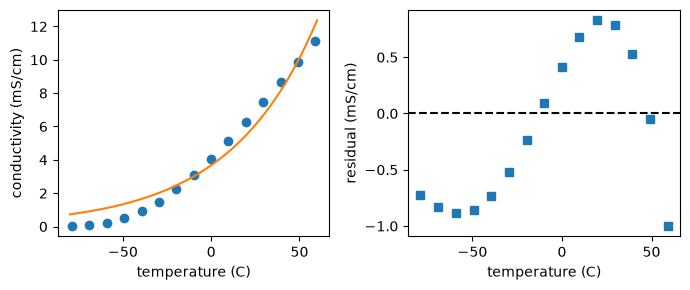

In [13]:
t_line = np.linspace(-80, 60, 200)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].plot(temperature, conductivity, 'o')
axes[0].plot(t_line, conductivity_model(t_line, *popt))
axes[0].set_xlabel('temperature (C)')
axes[0].set_ylabel('conductivity (mS/cm)')
axes[1].plot(temperature, residuals, 's')
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set_xlabel('temperature (C)')
axes[1].set_ylabel('residual (mS/cm)')
fig.tight_layout()
plt.show()

The left panel shows the readings (circles) and the curve from the first fit (line).
The right panel shows `residuals` of the first fit, the reading minus the curve.

**2d (5 points).** What does `popt[1]` tell you about how the conductivity depends on temperature?

<details><summary>Hint 1</summary>

`popt` follows the order of the parameters in the `def` line.

<details><summary>Hint 2</summary>

`b` multiplies the temperature inside the exponential, and it prints as 0.0202.

<details><summary>Answer</summary>

`popt[1]` is `b`, the second parameter in the `def` line, about 0.0202 per C.
The conductivity grows exponentially with temperature, by about 2% for each extra degree C.

</details>
</details>
</details>

**2e (8 points).** Why do the values printed by line 10 give a poor fit to the readings?

<details><summary>Hint 1</summary>

Compare the values printed by line 10 with the good fit printed by line 7.

<details><summary>Hint 2</summary>

The model is `a` times something. What is that product when `a` is about 0?

<details><summary>Answer</summary>

At 0 C the model gives `a`, which is about 0, but the readings near 0 C are several mS/cm, so the curve lies far below the data.
Also valid: the curve starts near 0 instead of near the good fit's 3.67 mS/cm, so it cannot pass through the readings.

</details>
</details>
</details>

**2f (7 points).** What does the pattern in the residual panel tell you about the exponential model?

<details><summary>Hint 1</summary>

A residual is the reading minus the curve, so a negative residual means the curve is above the reading.

<details><summary>Hint 2</summary>

Look at where the residuals are negative and where they are positive across the temperatures.

<details><summary>Answer</summary>

The residuals are not random scatter around zero.
They are negative at both ends and positive in the middle, so the curve sits above the readings at the ends and below them in the middle.
The exponential shape does not match the shape of these readings.

</details>
</details>
</details>

**2g (5 points).** Line 6 uses `popt.size` without parentheses, and line 7 uses `popt.round(4)` with parentheses. Why?

<details><summary>Hint 1</summary>

One of them is a value stored on the array, and the other is something the array does for you.

<details><summary>Hint 2</summary>

Something the array does is called with parentheses.

<details><summary>Answer</summary>

`size` is an attribute, a value stored on the array, so it needs no call.
`round` is a method, an action the array performs, so it is called with parentheses.

</details>
</details>
</details>

# 3. Fitting with minimize (25 points)

`proof_GPa` (0.2% proof stress) and `tensile_GPa` (tensile strength) hold tests of 95 low-alloy steels at 27 C, in GPa.
The code fits the line tensile = a + b proof by minimizing the sum of squared residuals.
`rmse` is the function from class.

*Data: NIMS [MatNavi](https://mits.nims.go.jp/en/), tensile tests on low-alloy steels.*

## Warm-up (no points)

**3a.** What does this print?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.x[0].round(2))
```

In [ ]:
# Check 3a
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.x[0].round(2))

**3b.** What happens when this runs?
```python
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.success())
```

In [ ]:
# Check 3b
# EXPECTED-ERROR: res.success is a bool, and a bool cannot be called
def f(x):
    return (x - 4)**2

res = optimize.minimize(f, 1)
print(res.success())

**3c.** Fill in the NumPy function that makes the objective a sum of squared residuals.
```python
def objective(params):
    residuals = y - model(x, *params)
    return np.________(residuals**2)
```

In [ ]:
# Check 3c
residuals = np.array([1.0, -2.0, 2.0])
print(np.sum(residuals**2))

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It loads the data for the cell below.

In [17]:
#@title Load the steel data (click ▶ to run) { display-mode: "form" }
steels = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/steels.csv')
at_27 = steels.loc[steels[' Temperature (°C)'] == 27]  # note the leading space in the column names
proof_GPa = at_27[' 0.2% Proof Stress (MPa)'].to_numpy() / 1000
tensile_GPa = at_27[' Tensile Strength (MPa)'].to_numpy() / 1000

def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

In [18]:
def sum_sq(params):
    a, b = params
    tensile_model = a + b * proof_GPa
    residuals = tensile_GPa - tensile_model
    return np.sum(residuals**2)

res = optimize.minimize(sum_sq, [0, 1])
print(res.x.round(2))     # prints [0.23 0.83]
print(res.success)        # prints True

tensile_fit = res.x[0] + res.x[1] * proof_GPa
print(rmse(tensile_GPa, tensile_fit).round(4))   # prints 0.0275

[0.23 0.83]
True
0.0275


Suppose the 0.83 GPa tensile strength (the largest one) had been mistyped as 8.3 GPa.
Refitting with least squares, and with a mean-absolute-error objective (`method='Nelder-Mead'`, as in class), would print:

```text
least squares: [-0.16  1.95]
minimum MAE:   [0.23 0.81]
```

**3d (4 points).** What does the 0.0275 printed by line 12 tell you about the fit?

<details><summary>Hint 1</summary>

RMSE is in the units of the readings.

<details><summary>Hint 2</summary>

Say how far a typical steel's tensile strength sits from the line.

<details><summary>Answer</summary>

A typical steel's tensile strength sits about 0.03 GPa (27 MPa) from the fitted line.

</details>
</details>
</details>

**3e (6 points).** What does `res.success` printing True on line 9 tell you?

<details><summary>Hint 1</summary>

`success` reports on the solver, not on the model.

<details><summary>Hint 2</summary>

What would you look at to judge whether a line suits these steels?

<details><summary>Answer</summary>

`True` only says the solver met its stopping test.
It does not say whether a line is the right shape for the steels.

</details>
</details>
</details>

**3f (10 points).** Why does the mistyped reading change the least-squares values a lot but the minimum-MAE values hardly at all?

<details><summary>Hint 1</summary>

Least squares adds up squared residuals, and MAE adds up absolute residuals.

<details><summary>Hint 2</summary>

Compare how much a residual ten times larger counts in each sum.

<details><summary>Answer</summary>

Least squares squares each residual, so the one huge residual dominates the sum and pulls `a` and `b` toward it.
In MAE a residual counts only in proportion to its size, so the other 94 readings still control that fit.

</details>
</details>
</details>

**3g (5 points).** Name one check, before fitting, that would have caught the 8.3 GPa reading.

<details><summary>Hint 1</summary>

The check must happen before the fit and must show every reading, or the extremes of them.

<details><summary>Hint 2</summary>

A plot, or a printed minimum and maximum, are two such checks.

<details><summary>Answer</summary>

Plot the tensile strength against the proof stress before fitting, where the 8.3 GPa point sits far above the others.
Printing the largest tensile strength, or sorting the values, would also catch it.

</details>
</details>
</details>

# 4. Fitting a plane (25 points)

`cement` (kg/m$^3$), `age` (days) and `strength` (MPa) hold 234 concrete mixes that contain fly ash and no slag.
The code fits the plane strength = a + b cement + c age by minimizing the mean squared residual.
`rmse` is the function from class.

*Data: I-Cheng Yeh, Cement and Concrete Research 28 (1998) 1797-1808, via the UCI Machine Learning Repository (CC BY 4.0).*

## Warm-up (no points)

**4a.** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(0, 1, 3, 4, 5))
```

In [ ]:
# Check 4a
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(0, 1, 3, 4, 5))

**4b.** Fill in the keyword that colors each point by the values in `z`.
```python
fig, ax = plt.subplots()
ax.scatter(x, y, ____=z, cmap='viridis')
```

In [ ]:
# Check 4b
x = np.array([1, 2, 3])
y = np.array([1, 2, 3])
z = np.array([5, 6, 7])
fig, ax = plt.subplots()
ax.scatter(x, y, c=z, cmap='viridis')
plt.show()

**4c.** What does this print?
```python
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(1, 0, *[3, 4, 5]))
```

In [ ]:
# Check 4c
def plane(x, y, a, b, c):
    return a + b * x + c * y

print(plane(1, 0, *[3, 4, 5]))

## Exam-style cell (25 points)

Read the code and its printed results before answering.

Run this cell first.
It loads the data for the cell below.

In [22]:
#@title Load the concrete data (click ▶ to run) { display-mode: "form" }
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/concrete.csv')
data.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
                'coarse_agg', 'fine_agg', 'age', 'strength']
is_fly_ash = (data['fly_ash'] > 0) & (data['slag'] == 0)
mixes = data.loc[is_fly_ash]
cement = mixes['cement']
age = mixes['age']
strength = mixes['strength']

def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

In [23]:
def plane(x, y, a, b, c):
    return a + b * x + c * y

def mse_plane(params):
    a, b, c = params
    residuals = strength - plane(cement, age, a, b, c)
    return np.mean(residuals**2)

res = optimize.minimize(mse_plane, [0, 0, 0])
a_fit, b_fit, c_fit = res.x
print(b_fit.round(3))      # prints 0.13
print(c_fit.round(3))      # prints 0.288

strength_fit = plane(cement, age, *res.x)
print(rmse(strength, strength_fit).round(2))           # prints 7.31
print(rmse(strength, np.mean(strength)).round(2))      # prints 13.41
print(np.max(cement))                                  # prints 505.0
print(np.max(age))                                     # prints 100
print(plane(400, 365, *res.x).round(1))                # prints 147.4

0.13
0.288
7.31
13.41
505.0
100
147.4


**4d (4 points).** What does the 0.13 printed by line 11 mean for the strength?

<details><summary>Hint 1</summary>

Read the units: MPa per kg/m$^3$ of cement.

<details><summary>Hint 2</summary>

Say what the plane predicts for 1 kg/m$^3$ more cement, with the age unchanged.

<details><summary>Answer</summary>

At the same age, the plane predicts about 0.13 MPa more strength for each extra kg/m$^3$ of cement.

</details>
</details>
</details>

**4e (7 points).** Line 12 prints 0.288, more than twice the 0.13. Why does that alone not show that age matters more than cement?

<details><summary>Hint 1</summary>

`b` is per kg/m$^3$ and `c` is per day.

<details><summary>Hint 2</summary>

Think about how far each input varies in the data: cement from about 135 to 505 kg/m$^3$, age from 3 to 100 days.

<details><summary>Answer</summary>

The two coefficients have different units, MPa per kg/m$^3$ and MPa per day, so their sizes cannot be compared directly.
The effect of each input also depends on how far it varies in the data.
Cement spans about 370 kg/m$^3$, which moves the plane by about 48 MPa, and age spans 97 days, which moves it by about 28 MPa.

</details>
</details>
</details>

**4f (7 points).** The plane's RMSE is 7.31 MPa. Guessing the mean strength for every mix gives 13.41 MPa. What can you conclude about the plane?

<details><summary>Hint 1</summary>

Both numbers are typical misses, in the same units.

<details><summary>Hint 2</summary>

About how many times smaller is the plane's miss?

<details><summary>Answer</summary>

The plane's typical miss is about half the miss from guessing the mean, so cement and age explain much of the variation in strength.
A typical miss of about 7 MPa remains.

</details>
</details>
</details>

**4g (7 points).** Why should you not rely on the 147.4 MPa prediction printed by line 19?

<details><summary>Hint 1</summary>

Compare the 400 and 365 in line 19 with the largest values printed by lines 17 and 18.

<details><summary>Hint 2</summary>

Which of the two inputs lies outside the data?

<details><summary>Answer</summary>

An age of 365 days is beyond the largest age in the data, 100 days (line 18), so the plane was never checked there.

</details>
</details>
</details>